## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Load and Verify

In [2]:
projects = pd.read_csv("residential_projects.csv")

projects.shape

(806, 20)

In [3]:
EXPECTED_TYPES = {"Duplex", "Single-Detached House", "Townhouse"}

print("Shape:", projects.shape)
print("Project types:", set(projects["project_type"].unique()) == EXPECTED_TYPES)
print("project_id unique:", projects["project_id"].is_unique)
print("Total missing values:", projects.isna().sum().sum())
print(projects.dtypes)

Shape: (806, 20)
Project types: True
project_id unique: True
Total missing values: 0
project_id                      object
project_type                    object
province                        object
city                            object
floor_area_sqm                 float64
number_of_storeys                int64
structure_type                  object
finish_tier                     object
project_scope                   object
estimated_duration_weeks         int64
estimated_cost_per_sqm_php     float64
estimated_total_cost_php       float64
structural_works_php           float64
architectural_finishing_php    float64
electrical_works_php           float64
plumbing_sanitary_php          float64
mechanical_works_php           float64
labor_cost_php                 float64
general_requirements_php       float64
other_costs_php                float64
dtype: object


## 2. Leakage Check

In [4]:
components = ["structural_works_php", "architectural_finishing_php", "electrical_works_php",
              "plumbing_sanitary_php", "mechanical_works_php", "labor_cost_php",
              "general_requirements_php", "other_costs_php"]

gap_components = (projects[components].sum(axis=1) - projects["estimated_total_cost_php"]).abs().max()
gap_rate = (projects["estimated_cost_per_sqm_php"] * projects["floor_area_sqm"]
            - projects["estimated_total_cost_php"]).abs().max()

print("Max gap, components vs total (PHP):", round(gap_components, 2))
print("Max gap, rate x area vs total (PHP):", round(gap_rate, 2))

Max gap, components vs total (PHP): 0.0
Max gap, rate x area vs total (PHP): 0.01


## 3. Target, Features, Forbidden List

In [5]:
TARGET_RAW = "estimated_cost_per_sqm_php"

numeric_features = ["floor_area_sqm", "number_of_storeys"]
categorical_features = ["project_type", "structure_type", "finish_tier",
                        "project_scope", "province"]

FORBIDDEN = ["project_id", "city", "estimated_total_cost_php",
             "estimated_cost_per_sqm_php", "estimated_duration_weeks"] + components

assert not set(FORBIDDEN) & set(numeric_features + categorical_features), "Leakage: forbidden column in X"

X = projects[numeric_features + categorical_features].copy()
y = np.log(projects[TARGET_RAW])

print("X shape:", X.shape, "| y shape:", y.shape)
print("Columns in X:", X.columns.tolist())

X shape: (806, 7) | y shape: (806,)
Columns in X: ['floor_area_sqm', 'number_of_storeys', 'project_type', 'structure_type', 'finish_tier', 'project_scope', 'province']


## 4. Train/Test Split

### Build the strata labels

In [6]:
from sklearn.model_selection import train_test_split

strata = projects["finish_tier"] + " | " + projects["project_scope"]
print(strata.value_counts().sort_values().head(5))
print("Number of strata:", strata.nunique())

High-End | Major Renovation or Fit-Out                    8
High-End | Shell and Core                                17
High-End | House Extension or Additional Floor           17
High-End | Turnkey Construction with Basic Site Works    24
Low-Cost | Major Renovation or Fit-Out                   29
Name: count, dtype: int64
Number of strata: 15


### Split with a fixed random seed

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=strata,
)

# Keep the real PHP totals for the final evaluation
total_test = projects.loc[X_test.index, "estimated_total_cost_php"]
area_test = projects.loc[X_test.index, "floor_area_sqm"]

### Check that the split is fair

In [8]:
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Do tiers have the same mix in both sets?
print(pd.concat([X_train["finish_tier"].value_counts(normalize=True).rename("train"),
                 X_test["finish_tier"].value_counts(normalize=True).rename("test")], axis=1).round(3))

# Does the target look the same in both?
print("y mean  train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("y std   train/test:", round(y_train.std(), 3), round(y_test.std(), 3))

# Rare categories: is each one present in train?
for col in ["structure_type", "province"]:
    missing = set(X_test[col]) - set(X_train[col])
    print(col, "-> in test but never in train:", missing or "none")
print(X_train["structure_type"].value_counts().tail(2))

Train: (644, 7) | Test: (162, 7)
             train  test
finish_tier             
Mid-Range     0.45  0.44
Low-Cost      0.37  0.37
High-End      0.18  0.18
y mean  train/test: 10.232 10.221
y std   train/test: 0.402 0.409
structure_type -> in test but never in train: none
province -> in test but never in train: none
structure_type
Steel Frame                  23
Timber or Engineered Wood    14
Name: count, dtype: int64


## 5. Preprocessing and the Province Experiment

### Imports and check the Metro Manila label

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import StratifiedKFold, cross_validate

In [10]:
print(sorted(X_train["province"].unique()))

['Albay', 'Batangas', 'Benguet', 'Bohol', 'Bulacan', 'Cavite', 'Cebu', 'Davao del Norte', 'Davao del Sur', 'Iloilo', 'La Union', 'Laguna', 'Metro Manila', 'Misamis Oriental', 'Negros Occidental', 'Nueva Ecija', 'Pampanga', 'Pangasinan', 'Rizal']


### Reusable pipeline builder

In [11]:
METRO = "Metro Manila"
assert METRO in X_train["province"].unique()

def make_pipeline(num_cols, cat_cols, model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

### Three versions of the inputs (province options)

In [12]:
num_cols = ["floor_area_sqm", "number_of_storeys"]
base_cat = ["project_type", "structure_type", "finish_tier", "project_scope"]

variants = {
    "A: full province":      (X_train,                                                              base_cat + ["province"]),
    "B: Metro vs other":     (X_train.assign(region_group=np.where(X_train["province"] == METRO,
                                                                    "Metro Manila", "Other")),     base_cat + ["region_group"]),
    "C: no location":        (X_train,                                                              base_cat),
}

### Cross-validation with the same folds for every option

In [13]:
strata_train = strata.loc[X_train.index]
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
             .split(X_train, strata_train))

scoring = {"mae": "neg_mean_absolute_error", "r2": "r2"}
rows = []

# Dummy baseline: always predicts the average
dummy = make_pipeline(num_cols, base_cat, DummyRegressor())
res = cross_validate(dummy, X_train, y_train, cv=folds, scoring=scoring)
rows.append({"option": "Dummy (average)", "MAE_log": -res["test_mae"].mean(),
             "MAE_std": res["test_mae"].std(), "R2": res["test_r2"].mean()})

for name, (Xv, cats) in variants.items():
    pipe = make_pipeline(num_cols, cats, Ridge(alpha=1.0))
    res = cross_validate(pipe, Xv, y_train, cv=folds, scoring=scoring)
    rows.append({"option": name, "MAE_log": -res["test_mae"].mean(),
                 "MAE_std": res["test_mae"].std(), "R2": res["test_r2"].mean()})

display(pd.DataFrame(rows).round(4))

,option,MAE_log,MAE_std,R2
0,Dummy (average),0.34,0.01,-0.00
1,A: full province,0.05,0.00,0.97
2,B: Metro vs other,0.06,0.00,0.97
3,C: no location,0.07,0.00,0.95


In [14]:
pd.reset_option("display.float_format")
pd.set_option("display.precision", 4)

## 6. Compare the Four Models

### Imports and model list

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score

models = {
    "Linear":            LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

### Evaluation function (log scale and PHP)

In [16]:
def evaluate(pipe, Xv):
    pred = cross_val_predict(pipe, Xv, y_train, cv=folds)   # each row predicted by a model that never saw it
    err = pred - y_train
    rate_true, rate_pred = np.exp(y_train), np.exp(pred)
    area = X_train["floor_area_sqm"]
    return {
        "MAE_log":       err.abs().mean(),
        "MAE_log_std":   np.std([err.iloc[te].abs().mean() for _, te in folds]),
        "RMSE_log":      np.sqrt((err ** 2).mean()),
        "R2_log":        r2_score(y_train, pred),
        "MAPE_%":        (rate_pred / rate_true - 1).abs().mean() * 100,
        "MAE_PHP_sqm":   (rate_pred - rate_true).abs().mean(),
        "MAE_PHP_total": ((rate_pred - rate_true) * area).abs().mean(),
    }

### Run all models on all three input variants

In [17]:
rows = []
for model_name, model in models.items():
    for var_name, (Xv, cats) in variants.items():
        pipe = make_pipeline(num_cols, cats, model)
        rows.append({"model": model_name, "inputs": var_name, **evaluate(pipe, Xv)})

results = pd.DataFrame(rows).sort_values("MAE_log").reset_index(drop=True)
display(results.round({"MAE_log": 4, "MAE_log_std": 4, "RMSE_log": 4, "R2_log": 4,
                       "MAPE_%": 2, "MAE_PHP_sqm": 0, "MAE_PHP_total": 0}))

,model,inputs,MAE_log,MAE_log_std,RMSE_log,R2_log,MAPE_%,MAE_PHP_sqm,MAE_PHP_total
0,Linear,A: full province,0.0522,0.0025,0.0658,0.9732,5.21,1542.0,205515.0
1,Ridge,A: full province,0.0522,0.0022,0.0658,0.9731,5.22,1540.0,205328.0
2,Ridge,B: Metro vs other,0.0573,0.0017,0.0719,0.9680,5.72,1679.0,226727.0
3,Linear,B: Metro vs other,0.0573,0.0017,0.0719,0.9680,5.72,1683.0,227303.0
4,Gradient Boosting,A: full province,0.0595,0.0021,0.0742,0.9659,5.95,1744.0,234430.0
5,Gradient Boosting,B: Metro vs other,0.0612,0.0020,0.0765,0.9638,6.11,1805.0,246772.0
6,Random Forest,A: full province,0.0689,0.0029,0.0847,0.9556,6.90,2038.0,273156.0
7,Random Forest,B: Metro vs other,0.0700,0.0021,0.0874,0.9527,6.99,2092.0,283949.0
8,Ridge,C: no location,0.0709,0.0031,0.0874,0.9527,7.08,2095.0,281274.0
9,Linear,C: no location,0.0710,0.0030,0.0874,0.9527,7.09,2099.0,281681.0


## 7. Residual diagnostics

### Out-of-fold predictions and signed errors

In [18]:
final_cats = base_cat + ["province"]
final_pipe = make_pipeline(num_cols, final_cats, Ridge(alpha=1.0))

pred = cross_val_predict(final_pipe, X_train, y_train, cv=folds)

diag = X_train.copy()
diag["pct_error"] = (np.exp(pred - y_train) - 1) * 100   # + means model too high
diag["abs_pct_error"] = diag["pct_error"].abs()

### Error by group

In [19]:
for col in ["finish_tier", "project_scope", "structure_type", "number_of_storeys", "project_type"]:
    display(diag.groupby(col).agg(n=("pct_error", "size"),
                                  bias_pct=("pct_error", "mean"),
                                  mape_pct=("abs_pct_error", "mean")).round(2))

diag["area_band"] = pd.qcut(diag["floor_area_sqm"], 4)
display(diag.groupby("area_band", observed=True).agg(n=("pct_error", "size"),
        bias_pct=("pct_error", "mean"), mape_pct=("abs_pct_error", "mean")).round(2))

prov_diag = (diag.groupby("province").agg(n=("pct_error", "size"),
             bias_pct=("pct_error", "mean"), mape_pct=("abs_pct_error", "mean"))
             .sort_values("bias_pct").round(2))
display(prov_diag)

,n,bias_pct,mape_pct
finish_tier,,,
High-End,119,-0.27,4.43
Low-Cost,237,0.51,5.68
Mid-Range,288,0.23,5.16


,n,bias_pct,mape_pct
project_scope,,,
House Extension or Additional Floor,69,0.08,5.10
Major Renovation or Fit-Out,53,1.22,5.41
New Complete Construction,318,0.11,5.32
Shell and Core,73,0.66,4.62
Turnkey Construction with Basic Site Works,131,0.03,5.31


,n,bias_pct,mape_pct
structure_type,,,
Load-Bearing Masonry,79,0.46,5.02
Reinforced Concrete Frame with CHB Infill,407,0.22,5.31
Reinforced Concrete Frame with Lightweight Partitions,121,0.22,4.99
Steel Frame,23,0.01,5.57
Timber or Engineered Wood,14,0.30,5.03


,n,bias_pct,mape_pct
number_of_storeys,,,
1,166,0.18,4.93
2,381,0.29,5.31
3,97,0.17,5.37


,n,bias_pct,mape_pct
project_type,,,
Duplex,131,0.15,5.55
Single-Detached House,340,0.24,4.97
Townhouse,173,0.30,5.47


,n,bias_pct,mape_pct
area_band,,,
"(45.099000000000004, 92.925]",161,0.41,4.91
"(92.925, 119.1]",161,-0.08,5.73
"(119.1, 160.575]",161,0.21,5.26
"(160.575, 385.6]",161,0.44,4.98


,n,bias_pct,mape_pct
province,,,
Benguet,19,-0.26,7.23
Rizal,37,-0.05,5.05
Laguna,61,-0.05,4.55
Bulacan,38,0.08,5.01
Misamis Oriental,17,0.10,4.21
Cebu,54,0.17,4.87
Metro Manila,171,0.19,5.57
Pampanga,44,0.19,5.15
Cavite,57,0.24,5.62


### Overall shape and worst cases

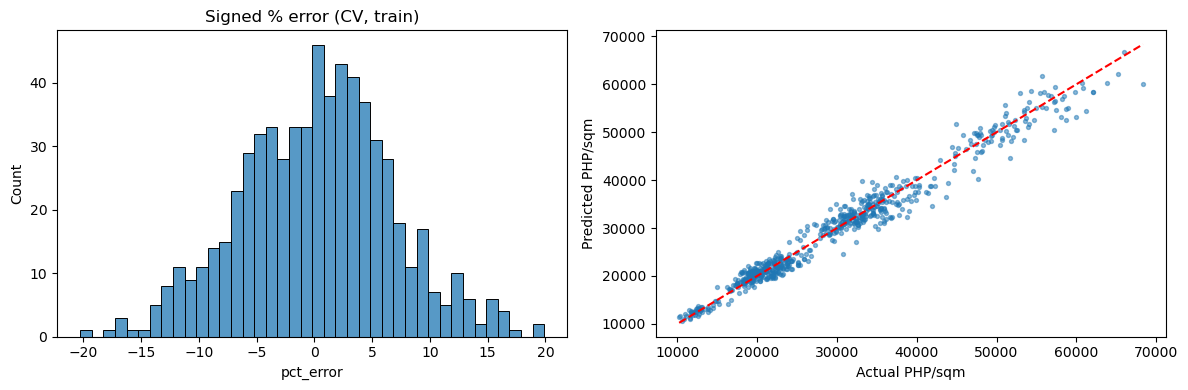

,project_type,province,finish_tier,project_scope,floor_area_sqm,actual,predicted,pct_error
798,Townhouse,Metro Manila,Low-Cost,Turnkey Construction with Basic Site Works,183.1,30707.0,24482.5,-20.3
747,Duplex,Metro Manila,Mid-Range,Turnkey Construction with Basic Site Works,145.9,33149.0,39740.0,19.9
81,Duplex,Albay,Low-Cost,House Extension or Additional Floor,187.1,14939.8,17763.2,18.9
698,Single-Detached House,Iloilo,Mid-Range,Turnkey Construction with Basic Site Works,251.0,41878.6,34494.2,-17.6
100,Single-Detached House,Laguna,Mid-Range,New Complete Construction,178.6,29073.7,33996.6,16.9
519,Townhouse,Bohol,Mid-Range,New Complete Construction,186.3,29901.2,34923.9,16.8
376,Duplex,Cebu,Mid-Range,New Complete Construction,104.6,38729.9,32380.7,-16.4
488,Single-Detached House,Benguet,Mid-Range,Turnkey Construction with Basic Site Works,121.2,31914.5,37122.1,16.3


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(diag["pct_error"], bins=40, ax=ax[0]); ax[0].set_title("Signed % error (CV, train)")
ax[1].scatter(np.exp(y_train), np.exp(pred), s=8, alpha=0.5)
lims = [np.exp(y_train).min(), np.exp(y_train).max()]
ax[1].plot(lims, lims, "r--"); ax[1].set_xlabel("Actual PHP/sqm"); ax[1].set_ylabel("Predicted PHP/sqm")
plt.tight_layout(); plt.show()

display(diag.assign(actual=np.exp(y_train), predicted=np.exp(pred))
        .nlargest(8, "abs_pct_error")[["project_type", "province", "finish_tier", "project_scope",
                                        "floor_area_sqm", "actual", "predicted", "pct_error"]].round(1))

## 8. Final test, uncertainty band, and saving the model

### Quick alpha check (train only, last choice before the test)

In [21]:
for a in [0.1, 1, 10, 30]:
    p = cross_val_predict(make_pipeline(num_cols, final_cats, Ridge(alpha=a)), X_train, y_train, cv=folds)
    print("alpha", a, "-> CV MAPE %:", round((np.exp(p - y_train) - 1).abs().mean() * 100, 3))

alpha 0.1 -> CV MAPE %: 5.213
alpha 1 -> CV MAPE %: 5.22
alpha 10 -> CV MAPE %: 6.193
alpha 30 -> CV MAPE %: 9.312


### One-time final test

In [22]:
ALPHA = 1.0
final_pipe = make_pipeline(num_cols, final_cats, Ridge(alpha=ALPHA)).fit(X_train, y_train)

pred_log   = final_pipe.predict(X_test)
rate_pred  = np.exp(pred_log)
rate_true  = np.exp(y_test).values
total_pred = rate_pred * area_test.values
total_true = total_test.values

ape = np.abs(rate_pred / rate_true - 1) * 100
test_metrics = {
    "MAE_log":        float(np.mean(np.abs(pred_log - y_test))),
    "RMSE_log":       float(np.sqrt(np.mean((pred_log - y_test) ** 2))),
    "R2_log":         float(r2_score(y_test, pred_log)),
    "MAPE_pct":       float(ape.mean()),
    "MAE_PHP_sqm":    float(np.abs(rate_pred - rate_true).mean()),
    "MAE_PHP_total":  float(np.abs(total_pred - total_true).mean()),
    "median_total_PHP": float(np.median(total_true)),
}
print({k: round(v, 4) for k, v in test_metrics.items()})

# Baseline for context
dummy_test = make_pipeline(num_cols, final_cats, DummyRegressor()).fit(X_train, y_train)
print("Dummy MAPE %:", round((np.abs(np.exp(dummy_test.predict(X_test)) / rate_true - 1) * 100).mean(), 2))

# How uncertain is the test MAPE itself? (162 projects is a small exam)
rng = np.random.default_rng(RANDOM_STATE)
boot = [rng.choice(ape, size=len(ape), replace=True).mean() for _ in range(2000)]
print("Test MAPE 95% interval:", np.percentile(boot, [2.5, 97.5]).round(2))

# 80% error band built from CV errors, then checked on the test set
resid_log = y_train - pred                  # `pred` = out-of-fold predictions from Stage 5
q10, q90  = np.percentile(resid_log, [10, 90])
low, high = rate_pred * np.exp(q10), rate_pred * np.exp(q90)
print("Share of test projects inside the 80% band:", round(((rate_true >= low) & (rate_true <= high)).mean(), 3))

{'MAE_log': 0.0517, 'RMSE_log': 0.0658, 'R2_log': 0.9739, 'MAPE_pct': 5.2276, 'MAE_PHP_sqm': 1596.1182, 'MAE_PHP_total': 215833.1262, 'median_total_PHP': 3354305.305}
Dummy MAPE %: 35.74
Test MAPE 95% interval: [4.55 5.87]
Share of test projects inside the 80% band: 0.79


### Refit on all 806 rows and save the model

In [23]:
import joblib, json, sklearn

X_all = projects[num_cols + final_cats]
y_all = np.log(projects["estimated_cost_per_sqm_php"])

deploy_pipe = make_pipeline(num_cols, final_cats, Ridge(alpha=ALPHA)).fit(X_all, y_all)
joblib.dump(deploy_pipe, "buildwise_cost_model.joblib")

['buildwise_cost_model.joblib']

### Save the "model card" the app will use for validation

In [24]:
model_card = {
    "dataset_label": "SYNTHETIC - Benchmark Calibrated (not real project costs)",
    "model": f"Ridge(alpha={ALPHA}) on log(cost per sqm); total = rate x floor_area_sqm",
    "sklearn_version": sklearn.__version__,
    "features": num_cols + final_cats,
    "categories": {c: sorted(projects[c].unique().tolist()) for c in final_cats},
    "valid_storeys_by_type": {k: sorted(g.unique().tolist()) for k, g in projects.groupby("project_type")["number_of_storeys"]},
    "valid_structures_by_type": {k: sorted(g.unique().tolist()) for k, g in projects.groupby("project_type")["structure_type"]},
    "valid_storeys_by_structure": {k: sorted(g.unique().tolist()) for k, g in projects.groupby("structure_type")["number_of_storeys"]},
    "area_range_by_type": projects.groupby("project_type")["floor_area_sqm"].agg(["min", "max"]).round(1).to_dict("index"),
    "band_log_q10_q90": [float(q10), float(q90)],
    "test_metrics": test_metrics,
}
with open("buildwise_model_card.json", "w") as f:
    json.dump(model_card, f, indent=2)

### Reload and sanity-test (acts like the app will)

In [25]:
loaded = joblib.load("buildwise_cost_model.joblib")
example = pd.DataFrame([{
    "floor_area_sqm": 120, "number_of_storeys": 2, "project_type": "Townhouse",
    "structure_type": "Reinforced Concrete Frame with CHB Infill", "finish_tier": "Mid-Range",
    "project_scope": "New Complete Construction", "province": "Metro Manila",
}])
rate = float(np.exp(loaded.predict(example))[0])
print(f"Rate: {rate:,.0f} PHP/sqm | Total: {rate * 120:,.0f} PHP | "
      f"80% band: {rate * 120 * np.exp(q10):,.0f} to {rate * 120 * np.exp(q90):,.0f} PHP")

Rate: 35,931 PHP/sqm | Total: 4,311,714 PHP | 80% band: 3,979,176 to 4,697,822 PHP


## 9. Cost-breakdown engine (no ML)

### Build the share table (from training data)

In [26]:
components = ["structural_works_php", "architectural_finishing_php", "electrical_works_php",
              "plumbing_sanitary_php", "mechanical_works_php", "labor_cost_php",
              "general_requirements_php", "other_costs_php"]

shares = projects[components].div(projects["estimated_total_cost_php"], axis=0)
shares.columns = [c.replace("_php", "") for c in components]

share_table = shares.groupby([projects["finish_tier"], projects["project_scope"]]).mean()
share_table = share_table.div(share_table.sum(axis=1), axis=0)   # force each row to add to exactly 100%

print(share_table.round(4))
print("Row sums:", share_table.sum(axis=1).round(6).unique())

                                                        structural_works  \
finish_tier project_scope                                                  
High-End    House Extension or Additional Floor                   0.2127   
            Major Renovation or Fit-Out                           0.0808   
            New Complete Construction                             0.2134   
            Shell and Core                                        0.3738   
            Turnkey Construction with Basic Site Works            0.2119   
Low-Cost    House Extension or Additional Floor                   0.2616   
            Major Renovation or Fit-Out                           0.0822   
            New Complete Construction                             0.2616   
            Shell and Core                                        0.3744   
            Turnkey Construction with Basic Site Works            0.2610   
Mid-Range   House Extension or Additional Floor                   0.2509   
            

### How stable are these recipes?

In [27]:
spread = shares.groupby([projects["finish_tier"], projects["project_scope"]]).std()
print("Typical spread within a group (pct points):")
print((spread.mean() * 100).round(2))

# Test on held-out rows: how far is the recipe from each real project's breakdown?
train_idx, test_idx = X_train.index, X_test.index
tr_table = shares.loc[train_idx].groupby([projects.loc[train_idx, "finish_tier"],
                                          projects.loc[train_idx, "project_scope"]]).mean()
tr_table = tr_table.div(tr_table.sum(axis=1), axis=0)

keys = list(zip(projects.loc[test_idx, "finish_tier"], projects.loc[test_idx, "project_scope"]))
pred_share = tr_table.loc[keys].values
err_pp = np.abs(pred_share - shares.loc[test_idx].values) * 100
print("Mean abs error per component on test (pct points):")
print(pd.Series(err_pp.mean(axis=0), index=shares.columns).round(2))

Typical spread within a group (pct points):
structural_works           0.55
architectural_finishing    0.67
electrical_works           0.27
plumbing_sanitary          0.22
mechanical_works           0.06
labor_cost                 0.54
general_requirements       0.16
other_costs                0.56
dtype: float64
Mean abs error per component on test (pct points):
structural_works           0.47
architectural_finishing    0.59
electrical_works           0.21
plumbing_sanitary          0.18
mechanical_works           0.05
labor_cost                 0.42
general_requirements       0.15
other_costs                0.51
dtype: float64


### Breakdown function for the app

In [28]:
def cost_breakdown(total_php, finish_tier, project_scope, table=share_table):
    row = table.loc[(finish_tier, project_scope)]
    parts = (row * total_php).round(0)
    parts.iloc[-1] += round(total_php) - parts.sum()      # fix rounding so parts add up exactly
    return parts

print(cost_breakdown(4_311_714, "Mid-Range", "New Complete Construction"))

structural_works           1072648.0
architectural_finishing    1294408.0
electrical_works            346200.0
plumbing_sanitary           302300.0
mechanical_works             64798.0
labor_cost                  862521.0
general_requirements        215942.0
other_costs                 152897.0
Name: (Mid-Range, New Complete Construction), dtype: float64


### Save the recipes

In [29]:
share_table.to_csv("buildwise_component_shares.csv")

## 10. Duration

### Duration target (same split, same folds)

In [30]:
y_dur = np.log(projects["estimated_duration_weeks"])
y_dur_train, y_dur_test = y_dur.loc[X_train.index], y_dur.loc[X_test.index]

### Compare options with cross-validation

In [31]:
dur_variants = {"no province": base_cat, "with province": base_cat + ["province"]}
dur_models = {"Ridge": Ridge(alpha=1.0),
              "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)}

rows = []
for mname, model in dur_models.items():
    for vname, cats in dur_variants.items():
        p = cross_val_predict(make_pipeline(num_cols, cats, model), X_train, y_dur_train, cv=folds)
        w_pred, w_true = np.exp(p), np.exp(y_dur_train)
        rows.append({"model": mname, "inputs": vname,
                     "MAPE_%": (np.abs(w_pred / w_true - 1)).mean() * 100,
                     "MAE_weeks": np.abs(w_pred - w_true).mean(),
                     "R2_log": r2_score(y_dur_train, p)})

display(pd.DataFrame(rows).sort_values("MAPE_%").round(2))

,model,inputs,MAPE_%,MAE_weeks,R2_log
2,Gradient Boosting,no province,4.46,1.72,0.96
3,Gradient Boosting,with province,4.47,1.73,0.96
0,Ridge,no province,5.13,2.03,0.94
1,Ridge,with province,5.19,2.05,0.94


### Final test

In [32]:
DUR_CATS = base_cat   # no province: it added nothing in CV
def new_dur_model():
    return GradientBoostingRegressor(random_state=RANDOM_STATE)

In [40]:
dur_final = make_pipeline(num_cols, DUR_CATS, new_dur_model()).fit(X_train, y_dur_train)

w_pred = np.exp(dur_final.predict(X_test))
w_true = np.exp(y_dur_test).values
print("Test MAPE %:", round((np.abs(w_pred / w_true - 1) * 100).mean(), 2),
      "| MAE weeks:", round(np.abs(w_pred - w_true).mean(), 2),
      "| R2 (log):", round(r2_score(y_dur_test, np.log(w_pred)), 4))
print("Dummy MAPE %:", round((np.abs(np.exp(make_pipeline(num_cols, DUR_CATS, DummyRegressor())
      .fit(X_train, y_dur_train).predict(X_test)) / w_true - 1) * 100).mean(), 2))

Test MAPE %: 4.21 | MAE weeks: 1.65 | R2 (log): 0.9609
Dummy MAPE %: 20.77


In [41]:
p_cv = cross_val_predict(make_pipeline(num_cols, DUR_CATS, new_dur_model()),
                         X_train, y_dur_train, cv=folds)
q10_dur, q90_dur = np.percentile(y_dur_train - p_cv, [10, 90])
print("log band:", round(q10_dur, 4), round(q90_dur, 4))

lo, hi = w_pred * np.exp(q10_dur), w_pred * np.exp(q90_dur)
cov = ((w_true >= lo) & (w_true <= hi)).mean()
print("Share of test projects inside the 80% band:", round(cov, 3))

log band: -0.0728 0.0697
Share of test projects inside the 80% band: 0.87


### Refit and Save

In [42]:
dur_deploy = make_pipeline(num_cols, DUR_CATS, new_dur_model()).fit(
    projects[num_cols + DUR_CATS], y_dur.loc[projects.index])
joblib.dump(dur_deploy, "buildwise_duration_model.joblib")      # overwrites the Ridge file

with open("buildwise_model_card.json") as f:
    card = json.load(f)
card["duration_model"] = {
    "model": "GradientBoostingRegressor(random_state=42) on log(weeks); no province",
    "features": num_cols + DUR_CATS,
    "band_log_q10_q90": [float(q10_dur), float(q90_dur)],
    "test_mape_pct": float((np.abs(w_pred / w_true - 1) * 100).mean()),
    "test_mae_weeks": float(np.abs(w_pred - w_true).mean()),
    "note": "Synthetic duration data. Display predicted weeks rounded to whole weeks."}
with open("buildwise_model_card.json", "w") as f:
    json.dump(card, f, indent=2)

## 11. Schedule Engine

### Load and parse the template

In [43]:
tmpl = pd.read_excel("Additional_Data.xlsx", sheet_name="construction_schedule_template")
tmpl["wbs"] = tmpl["wbs"].astype(int)
tmpl["preds"] = tmpl["predecessor_wbs"].apply(
    lambda s: [] if pd.isna(s) else [int(float(x)) for x in str(s).split(";")])
tmpl["mid_days"] = (tmpl["duration_min_workdays"] + tmpl["duration_max_workdays"]) / 2

assert all(p < w for w, ps in zip(tmpl["wbs"], tmpl["preds"]) for p in ps)   # order is safe for one forward pass

### CPM function

In [44]:
def run_cpm(tmpl, keep):
    keep = set(keep)
    info = tmpl.set_index("wbs")

    def kept_preds(w):                          # reconnect around removed activities
        out, stack = set(), list(info.loc[w, "preds"])
        while stack:
            p = stack.pop()
            if p in keep: out.add(p)
            else: stack += info.loc[p, "preds"]
        return out

    preds = {w: kept_preds(w) for w in keep}
    dur = info["mid_days"].to_dict()

    es, ef = {}, {}
    for w in sorted(keep):                      # forward pass: earliest start / finish
        es[w] = max((ef[p] for p in preds[w]), default=0)
        ef[w] = es[w] + dur[w]
    total = max(ef.values())

    succs = {w: [v for v in keep if w in preds[v]] for w in keep}
    ls = {}
    for w in sorted(keep, reverse=True):        # backward pass: latest start
        lf = min((ls[s] for s in succs[w]), default=total)
        ls[w] = lf - dur[w]

    out = pd.DataFrame({"wbs": sorted(keep)})
    out["es_days"] = out["wbs"].map(es)
    out["dur_days"] = out["wbs"].map(dur)
    out["float_days"] = out["wbs"].map(lambda w: ls[w] - es[w])
    out["critical"] = np.isclose(out["float_days"], 0)
    return out, total

### Scope-to-activities rules (edit after your decision)

In [45]:
SCOPE_ACTIVITIES = {
    "New Complete Construction":                  range(1, 17),
    "Turnkey Construction with Basic Site Works": range(1, 17),
    "House Extension or Additional Floor":        range(1, 17),
    "Shell and Core":                             range(1, 12),
    "Major Renovation or Fit-Out":                [1, 2, 9, 10, 11, 12, 13, 14, 15, 16],
}

### Build a schedule scaled to the predicted weeks

In [46]:
def build_schedule(total_weeks, scope):
    cpm, total_days = run_cpm(tmpl, SCOPE_ACTIVITIES[scope])
    k = total_weeks / total_days                       # weeks per template workday
    s = cpm.merge(tmpl[["wbs", "activity"]], on="wbs")
    s["start_week"]    = s["es_days"] * k
    s["duration_weeks"] = s["dur_days"] * k
    s["end_week"]      = s["start_week"] + s["duration_weeks"]
    s["float_weeks"]   = s["float_days"] * k
    return s[["wbs", "activity", "start_week", "duration_weeks", "end_week", "float_weeks", "critical"]]

### Gantt chart

In [47]:
import plotly.graph_objects as go

def gantt(s, title):
    fig = go.Figure(go.Bar(
        y=s["activity"], x=s["duration_weeks"], base=s["start_week"], orientation="h",
        marker_color=np.where(s["critical"], "#d62728", "#1f77b4"),
        customdata=np.stack([s["float_weeks"].round(1)], axis=-1),
        hovertemplate="%{y}<br>Duration: %{x:.1f} wk<br>Float: %{customdata[0]} wk<extra></extra>"))
    fig.update_yaxes(autorange="reversed")
    fig.update_xaxes(title="Project week")
    fig.update_layout(title=title + " (illustrative schedule; red = critical path)", height=520)
    return fig

### Checks

In [48]:
for scope, weeks in [("New Complete Construction", 41), ("Shell and Core", 28), ("Major Renovation or Fit-Out", 28)]:
    s = build_schedule(weeks, scope)
    print(f"{scope}: ends at week {s['end_week'].max():.1f} | critical = {s.loc[s['critical'], 'wbs'].tolist()}")

s = build_schedule(41, "New Complete Construction")
display(s.round(1))
gantt(s, "New Complete Construction, 41 weeks").show()

New Complete Construction: ends at week 41.0 | critical = [1, 2, 3, 4, 5, 7, 9, 10, 11, 13, 14, 15, 16]
Shell and Core: ends at week 28.0 | critical = [1, 2, 3, 4, 5, 7, 9, 10, 11]
Major Renovation or Fit-Out: ends at week 28.0 | critical = [1, 2, 9, 10, 11, 13, 14, 15, 16]


,wbs,activity,start_week,duration_weeks,end_week,float_weeks,critical
0,1,Mobilization and site setup,0.0,2.1,2.1,0.0,True
1,2,Site clearing and layout,2.1,1.2,3.3,0.0,True
2,3,Excavation and earthworks,3.3,2.1,5.4,0.0,True
3,4,"Formworks, rebar and foundation preparation",5.4,3.1,8.4,0.0,True
4,5,Foundation concrete placement and initial curing,8.4,1.2,9.7,0.0,True
5,6,Backfilling and ground floor preparation,9.7,1.9,11.5,29.5,False
6,7,"Structural frame, columns, beams and slab",9.7,6.2,15.9,0.0,True
7,8,Roof framing and roofing,15.9,3.1,19.0,11.5,False
8,9,CHB walling and partitions,15.9,4.7,20.6,0.0,True
9,10,Electrical and plumbing rough-ins,20.6,4.3,24.9,0.0,True


## 12. One entry point for Phase 3 (buildwise_core.py)

### 1. Add two fields to the model card

### 2. Test the module from your notebook